# Phase calculation and comparison with theory for a single trajectory (CPU / Numba)

Estimate c, B, and the phases from a single trajectory of two coupled systems with noise. Run the cells from top to bottom.

## 1. Setup
Run this notebook with `SampleCode/` as the working directory.

In [1]:
from pathlib import Path
import time

import numpy as np
import matplotlib.pyplot as plt

from spde_cpu import simulate
from scipy.interpolate import interp1d
from phase_analysis import (
    calculate_Theta, calculate_c, calculate_b, concatenate_theta_b,
    fit_B_function, calculate_Phi, get_common_time, solve_theory, wrap_period,
)
from run_single_trajectory import initial_states_from_phases, integer_steps

%matplotlib inline

TEST_DIR = Path('.')
DATA_DIR = TEST_DIR / 'data'

## 2. Parameters
`T_END` is the final value of the rescaled time $\epsilon t$. `DT` is the integration time step, and `SAVE_INTERVAL` is the output sampling interval, both in physical time $t$.
Specify the initial phases using `Phi_i_over_L` (Φᵢ/L) and `Theta_i_over_pi` (Θᵢ/π). The spatial domain is `[-L, L]`, with `L=125`.

In [2]:
# If saved CSV files are available, set loaddata to True to load them.
# Otherwise, set it to False to run the SPDE simulation.
loaddata = False

if loaddata:
    print("Saved data will be loaded from CSV files and plotted.")
    print("The settings in the code block below will be ignored.")
else:
    print("The SPDE simulation will run. Existing output CSV files will be overwritten.")

The SPDE simulation will run. Existing output CSV files will be overwritten.


In [3]:
T_END = 2.0            # Final rescaled time, epsilon * t
SIGMA = 1e-6              # Noise amplitude; sigma**2 is the intensity. Set to 0 to disable noise.
Phi_1_over_L = 0.5       # System 1: Phi_1 / L (aligned with the grid)
Theta_1_over_pi = 0.0      # System 1: Theta_1 / pi (aligned with the grid)
Phi_2_over_L = 0.0         # System 2: Phi_2 / L
Theta_2_over_pi = 0.0      # System 2: Theta_2 / pi

In [4]:
DT = 0.01
SAVE_INTERVAL = 1.0
EPSILON = 1e-6
SECTION = 7.0            # Section for upward crossings used to define temporal phase
B_HARMONICS = 10         # Fourier order for B (cosine/sine terms, no constant term)
SEED = 12345

X0_PATH = DATA_DIR / 'X0_axes.csv'
COUPLING_PATH = DATA_DIR / 'MutualCouplingFunction_8193_axes.csv'
B_THEORY_PATH = DATA_DIR / 'B_theory.csv'
OUTPUT_DIR = TEST_DIR / 'output'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 3. Initial states
Start from
$$X_1=X_0(\Phi_1,\Theta_1),\qquad X_2=X_0(\Phi_2,\Theta_2).$$
Each phase is snapped to the nearest point on the periodic grid of the X0 data.

In [5]:
if not loaddata:
    rx = np.genfromtxt(X0_PATH, delimiter=',', names=True)['rx']
    DOMAIN_LENGTH = float(np.ptp(rx))
    L = DOMAIN_LENGTH / 2

    Phi_1, Theta_1 = Phi_1_over_L * L, Theta_1_over_pi * np.pi
    Phi_2, Theta_2 = Phi_2_over_L * L, Theta_2_over_pi * np.pi
    initial, rx, init_info = initial_states_from_phases(
        X0_PATH, Phi_1, Theta_1, Phi_2, Theta_2,
    )

## 4. Run the SPDE simulation or load saved data
If saved CSV files are available in `output/`, set `loaddata = True` to load them and skip the SPDE simulation. Otherwise, set `loaddata = False` to run the simulation.

In [ ]:
if loaddata:
    data = np.genfromtxt(OUTPUT_DIR / 'trajectory.csv', delimiter=',', names=True)
    moments = {name: data[name] for name in ('t', 'U1_bar', 'V1_bar', 'U2_bar', 'V2_bar')}
    for i in (1, 2):
        moments[f'A{i}_tilde'] = data[f'A{i}_tilde_real'] + 1j * data[f'A{i}_tilde_imag']

    data = np.genfromtxt(OUTPUT_DIR / 'parameters.csv', delimiter=',', names=True,
                         dtype=None, encoding='utf-8')
    parameters = dict(zip(data['name'], data['value']))
    DT = float(parameters['dt'])
    EPSILON = float(parameters['epsilon'])
    SIGMA = float(parameters['sigma'])
    SEED = int(float(parameters['seed']))
    SAVE_INTERVAL = float(parameters['save_interval'])
    DOMAIN_LENGTH = float(parameters['domain_length'])
    L = DOMAIN_LENGTH / 2
    simulation_seconds = float(parameters['simulation_seconds'])

    state = np.genfromtxt(OUTPUT_DIR / 'final_state.csv', delimiter=',', names=True)
    rx = np.append(state['rx'], state['rx'][0] + DOMAIN_LENGTH)
    moments['final_state'] = np.array([[state['U1'], state['V1']],
                                       [state['U2'], state['V2']]])
else:
    T_PHYSICAL = T_END / EPSILON
    N_STEPS = integer_steps(T_PHYSICAL, DT, 'T_END / EPSILON')
    SAVE_STRIDE = integer_steps(SAVE_INTERVAL, DT, 'SAVE_INTERVAL')
    started = time.perf_counter()
    moments = simulate(
        initial, rx, DT, N_STEPS, SAVE_STRIDE,
        epsilon=EPSILON, sigma=SIGMA, seed=SEED, progress=True,
    )
    simulation_seconds = time.perf_counter() - started

SPDE:   0%|          | 0.00/200M [00:00<?, ?step/s]

In [ ]:
if not loaddata:
    np.savetxt(
        OUTPUT_DIR / 'trajectory.csv',
        np.column_stack((
            moments['t'], moments['U1_bar'], moments['V1_bar'],
            moments['U2_bar'], moments['V2_bar'],
            moments['A1_tilde'].real, moments['A1_tilde'].imag,
            moments['A2_tilde'].real, moments['A2_tilde'].imag,
        )),
        delimiter=',', fmt='%.17g', comments='',
        header='t,U1_bar,V1_bar,U2_bar,V2_bar,A1_tilde_real,A1_tilde_imag,A2_tilde_real,A2_tilde_imag',
    )
    np.savetxt(
        OUTPUT_DIR / 'final_state.csv',
        np.column_stack((rx[:-1], *moments['final_state'].reshape(4, -1))),
        delimiter=',', fmt='%.17g', header='rx,U1,V1,U2,V2', comments='',
    )
    parameters = {
        'dt': DT, 'epsilon': EPSILON, 'sigma': SIGMA, 'seed': SEED,
        'save_interval': SAVE_INTERVAL, 'domain_length': DOMAIN_LENGTH,
        'Phi1_initial': init_info['phi1'], 'Theta1_initial': init_info['theta1'],
        'Phi2_initial': init_info['phi2'], 'Theta2_initial': init_info['theta2'],
        'simulation_seconds': simulation_seconds,
    }
    np.savetxt(
        OUTPUT_DIR / 'parameters.csv', np.array(list(parameters.items()), dtype=object),
        delimiter=',', fmt='%s', header='name,value', comments='',
    )

## 5. Phase calculation

### 5.1 Calculate Θ

In [ ]:
t = moments['t']
Theta1, mask1 = calculate_Theta(moments['U1_bar'], t, section=SECTION)
Theta2, mask2 = calculate_Theta(moments['U2_bar'], t, section=SECTION)
t1, t2 = t[mask1], t[mask2]

### 5.2 Estimate the translation speed c

In [ ]:
params = {'L': L}
c1 = calculate_c(moments['A1_tilde'], moments['U1_bar'], t, params, section=SECTION)
c2 = calculate_c(moments['A2_tilde'], moments['U2_bar'], t, params, section=SECTION)
print(f'c1 = {c1:.8g}')
print(f'c2 = {c2:.8g}')

c1 = 0.042955395
c2 = 0.042984888


### 5.3 Calculate b for each cycle

In [ ]:
b1 = calculate_b(moments['A1_tilde'][mask1], Theta1, t1,
                 {'L': L, 'c': c1})
b2 = calculate_b(moments['A2_tilde'][mask2], Theta2, t2,
                 {'L': L, 'c': c2})

### 5.4 Estimate the periodic correction function B

In [ ]:
bx1, by1 = concatenate_theta_b(b1)
bx2, by2 = concatenate_theta_b(b2)
B1 = fit_B_function(Theta=bx1, B=by1, M=B_HARMONICS)
B2 = fit_B_function(Theta=bx2, B=by2, M=B_HARMONICS)

### 5.5 Calculate Φ

In [ ]:
Bfunc1 = interp1d(B1['Bx'], B1['By'], kind='linear')
Bfunc2 = interp1d(B2['Bx'], B2['By'], kind='linear')
Phi1 = calculate_Phi(moments['A1_tilde'][mask1], Theta1, Bfunc1, params)
Phi2 = calculate_Phi(moments['A2_tilde'][mask2], Theta2, Bfunc2, params)

### 5.6 Calculate phase differences at common times

In [ ]:
common1, common2 = get_common_time(t1, t2)
t_phase = t1[common1]
delta_phi = wrap_period(Phi1[common1] - Phi2[common2], DOMAIN_LENGTH)
delta_theta = wrap_period(Theta1[common1] - Theta2[common2], 2 * np.pi)

### 5.7 Observed time series

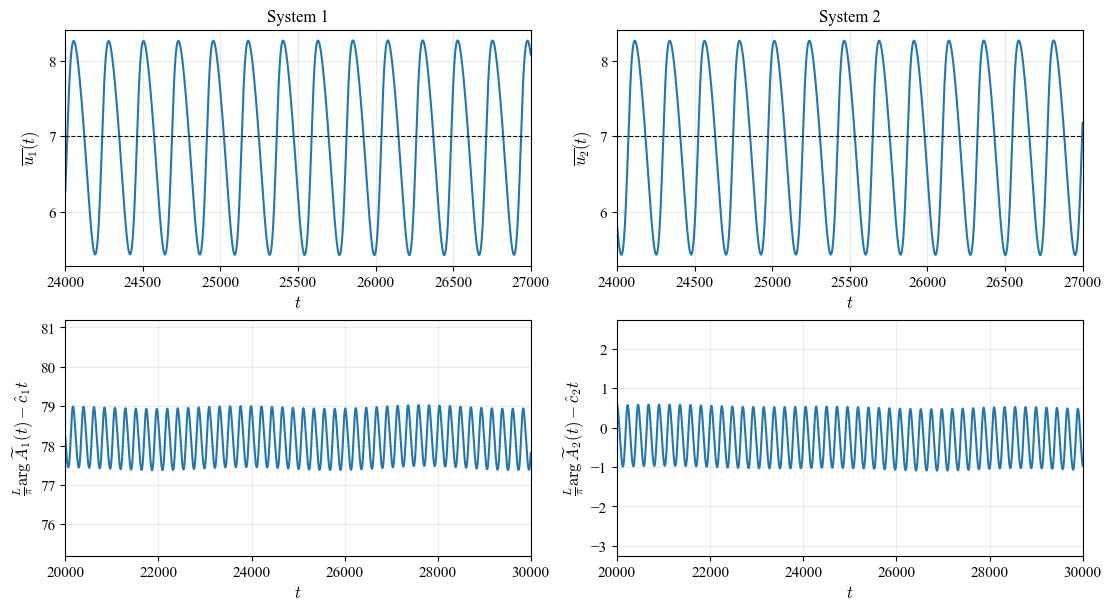

In [ ]:
t = moments['t']
arg_u = (24000 <= t) & (t <= 27000)
arg_a = (20000 <= t) & (t <= 30000)
timeseries_fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex='row', constrained_layout=True)
for j, (i, ci) in enumerate(((1, c1), (2, c2))):
    angle_a = np.unwrap(np.angle(moments[f'A{i}_tilde']))
    drift_removed = (L / np.pi) * angle_a[arg_a] - ci * t[arg_a]
    axes[0, j].plot(t[arg_u], moments[f'U{i}_bar'][arg_u])
    axes[0, j].set_xlim(24000, 27000)
    axes[0, j].axhline(SECTION, color='black', ls='--', lw=0.8)
    axes[0, j].set_ylabel(fr'$\overline{{u_{i}}}(t)$')
    axes[0, j].set_yticks([6, 7, 8])
    axes[0, j].set_title(f'System {i}')
    axes[1, j].plot(t[arg_a], drift_removed)
    axes[1, j].set_xlim(20000, 30000)
    center = (drift_removed.min() + drift_removed.max()) / 2
    axes[1, j].set_ylim(center - 3, center + 3)
    axes[1, j].set_ylabel(fr'$\frac{{L}}{{\pi}}\arg\widetilde A_{i}(t)-\hat c_{i}t$')
for ax in axes.flat:
    ax.set_xlabel(r'$t$')
    ax.grid(alpha=0.25)
plt.show()

### 5.8 Compare B with the theoretical curve

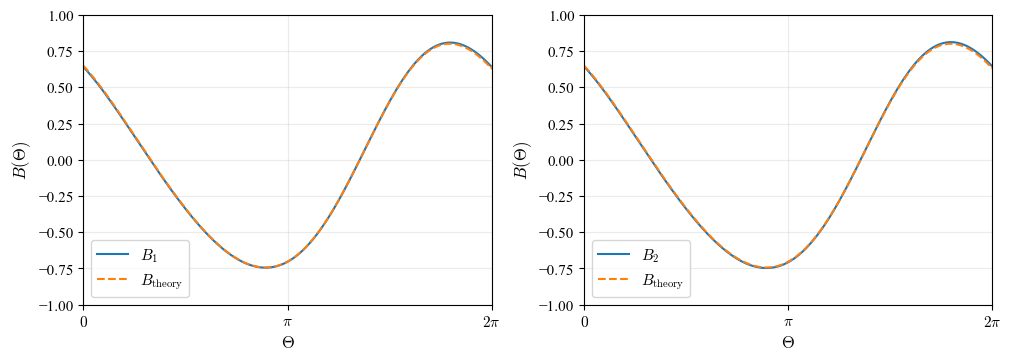

In [ ]:
b_theory = np.genfromtxt(B_THEORY_PATH, delimiter=',', names=True)
b_fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for i, (ax, Bi) in enumerate(zip(axes, (B1, B2)), start=1):
    ax.plot(Bi['Bx'], Bi['By'], label=fr'$B_{i}$')
    ax.plot(b_theory['theta'], b_theory['B_theory'], '--', label=r'$B_{\mathrm{theory}}$')
    ax.set(xlabel=r'$\Theta$', ylabel=r'$B(\Theta)$', xlim=(0, 2 * np.pi), ylim=(-1, 1))
    ax.set_xticks([0, np.pi, 2 * np.pi], [r'$0$', r'$\pi$', r'$2\pi$'])
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## 6. Theoretical prediction
Solve the averaged phase equations using the measured initial phase differences.

In [ ]:
theory = solve_theory(
    t_phase, [delta_phi[0], delta_theta[0]],
    COUPLING_PATH, EPSILON, DOMAIN_LENGTH,
)

## 7. Time series of phase differences
Phase differences are defined as system 1 minus system 2. The horizontal axis shows $\epsilon t$.

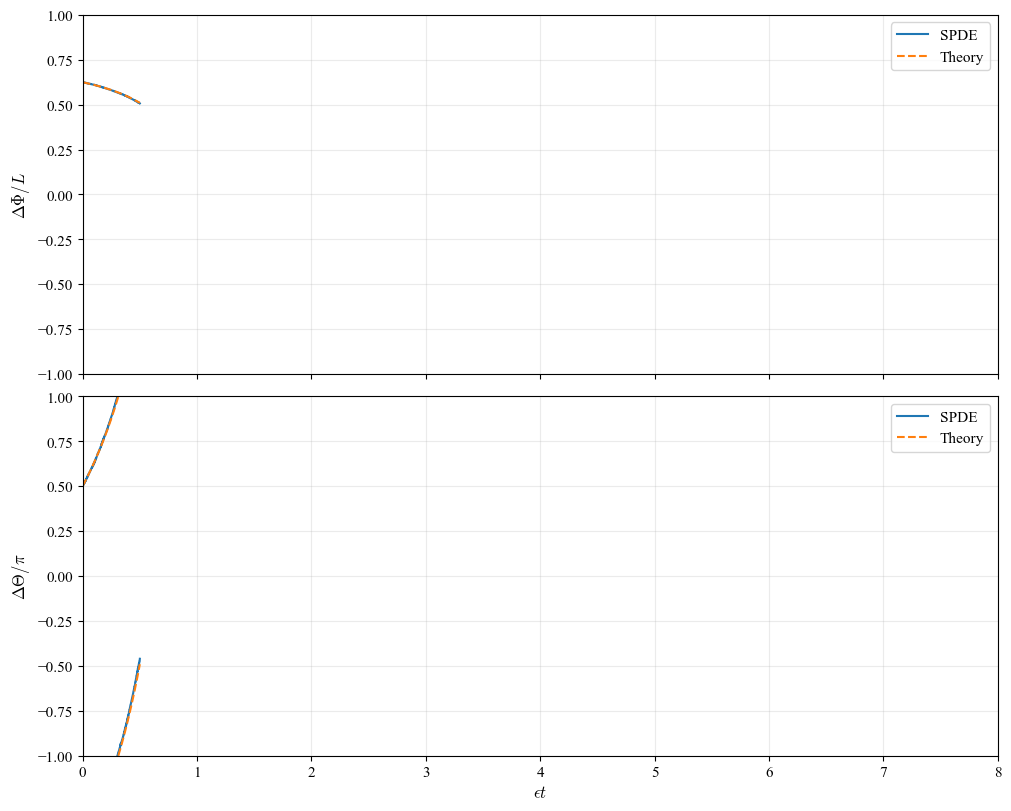

In [ ]:
comparison_fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
x = EPSILON * t_phase

for i, (observed, period, scale, label) in enumerate((
    (delta_phi, DOMAIN_LENGTH, L, r'$\Delta\Phi/L$'),
    (delta_theta, 2 * np.pi, np.pi, r'$\Delta\Theta/\pi$'),
)):
    for y, name, style in (
        (observed, 'SPDE', '-'),
        (wrap_period(theory[i], period), 'Theory', '--'),
    ):
        # Do not connect lines across periodic boundaries
        jumps = np.flatnonzero(np.abs(np.diff(y)) > period / 2) + 1
        axes[i].plot(np.insert(x, jumps, np.nan), np.insert(y / scale, jumps, np.nan),
                     style, label=name)
    axes[i].set_ylabel(label)
    axes[i].legend()
    axes[i].grid(alpha=0.25)
    axes[i].set_xlim(0, 8)
    axes[0].set_ylim(-1, 1)
    axes[1].set_ylim(-1, 1)
axes[-1].set_xlabel(r'$\epsilon t$')
plt.show()

## 8. Save results
Save numerical data as CSV files and figures as PNG files in `output/`. Existing files with the same names will be overwritten.

In [ ]:
np.savetxt(
    OUTPUT_DIR / 'phase_comparison.csv',
    np.column_stack((
        t_phase, EPSILON * t_phase, delta_phi, delta_theta, theory[0], theory[1],
        Phi1[common1], Theta1[common1], Phi2[common2], Theta2[common2],
    )),
    delimiter=',', fmt='%.17g', comments='',
    header='t,eps_t,delta_phi,delta_theta,theory_delta_phi,theory_delta_theta,Phi1,Theta1,Phi2,Theta2',
)
np.savetxt(
    OUTPUT_DIR / 'B_estimated.csv', np.column_stack((B1['Bx'], B1['By'], B2['By'])),
    delimiter=',', fmt='%.17g', header='theta,B1,B2', comments='',
)
np.savetxt(
    OUTPUT_DIR / 'B_coefficients.csv',
    np.column_stack((np.arange(1, B_HARMONICS + 1),
                     B1['alpha'], B1['beta'], B2['alpha'], B2['beta'])),
    delimiter=',', fmt='%.17g', header='n,cos1,sin1,cos2,sin2', comments='',
)
np.savetxt(
    OUTPUT_DIR / 'B_samples.csv',
    np.column_stack((np.repeat([1, 2], [len(bx1), len(bx2)]),
                     np.concatenate((bx1, bx2)), np.concatenate((by1, by2)))),
    delimiter=',', fmt='%.17g', header='system,theta,b', comments='',
)
parameters.update({
    'c1': c1, 'c2': c2, 'section': SECTION,
    'b_method': 'estimated', 'b_source': 'estimated_from_trajectory',
    'b_harmonics': B_HARMONICS, 'b_trim_cycles': 1,
    'b_offset1': B1['offset'], 'b_offset2': B2['offset'],
    'b_fit_cycles1': len(b1), 'b_fit_cycles2': len(b2),
})
np.savetxt(
    OUTPUT_DIR / 'parameters.csv', np.array(list(parameters.items()), dtype=object),
    delimiter=',', fmt='%s', header='name,value', comments='',
)
timeseries_fig.savefig(OUTPUT_DIR / 'timeseries.png', dpi=180)
comparison_fig.savefig(OUTPUT_DIR / 'comparison.png', dpi=180)
b_fig.savefig(OUTPUT_DIR / 'B_estimation.png', dpi=180)

Main results: `moments` (trajectory), `Theta1`, `Theta2`, `Phi1`, and `Phi2` (phases), `c1` and `c2` (estimated translation speeds), `B1` and `B2` (estimated periodic correction functions), and `theory` (theoretical prediction).